# SciCite: Citation Intent Classification
## 04. In-Depth Error Analysis & Failure Mode Diagnostics

**Course:** Mesterséges intelligencia alkalmazási területei (MSc)
**Objective:** Quantitative and qualitative post-hoc failure analysis across all baseline and fine-tuned Transformer models on the official SciCite test set (1,859 instances).

### Analytical Dimensions Explored:
1. **Error Rate Stratification by Section Context:** Measuring vulnerability across the 7 canonical section categories and quantifying the "missing section penalty".
2. **Inter-Class Error Transition Dynamics:** Analyzing the primary confusion axes (`Method` $\leftrightarrow$ `Background` vs. `Result` $\leftrightarrow$ `Background`).
3. **Model Agreement & Disagreement:** Quantifying baseline errors rescued by contextual Transformers vs. universal hard instances where all models fail.
4. **Qualitative Case Studies:** Granular linguistic and contextual examination of representative failure modes.

In [1]:
# 1. Environment & Setup
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

reports_dir = PROJECT_ROOT / "outputs" / "reports"
errors_dir = PROJECT_ROOT / "outputs" / "errors"
figures_dir = PROJECT_ROOT / "outputs" / "figures"

print("Project paths verified successfully.")

Project paths verified successfully.


### 2. Error Rate Stratification by Canonical Section Type
We examine whether model reliability depends systematically on the location of the citation within the scientific document structure.

In [2]:
# Load section error rate report
section_err_df = pd.read_csv(reports_dir / "error_rate_by_section.csv")
display(section_err_df)

,Canonical Section,Count,Dataset Share (%),Error Rate - Baseline (Text-only) (%),Error Rate - Baseline (Section-aware) (%),Error Rate - DistilBERT (Section-aware) (%),Error Rate - ModernBERT (Section-aware) (%),Error Rate - SciBERT (Section-aware) (%)
0,discussion,777,41.80,13.90,14.03,14.80,14.67,15.06
1,method,412,22.16,18.69,7.04,8.25,5.34,9.71
2,result,310,16.68,19.35,19.68,18.71,15.16,18.39
3,other,118,6.35,16.95,17.80,16.95,14.41,16.95
4,introduction,89,4.79,13.48,11.24,11.24,13.48,12.36
5,result_discussion,77,4.14,11.69,10.39,15.58,11.69,12.99
6,missing,76,4.09,26.32,22.37,23.68,21.05,23.68


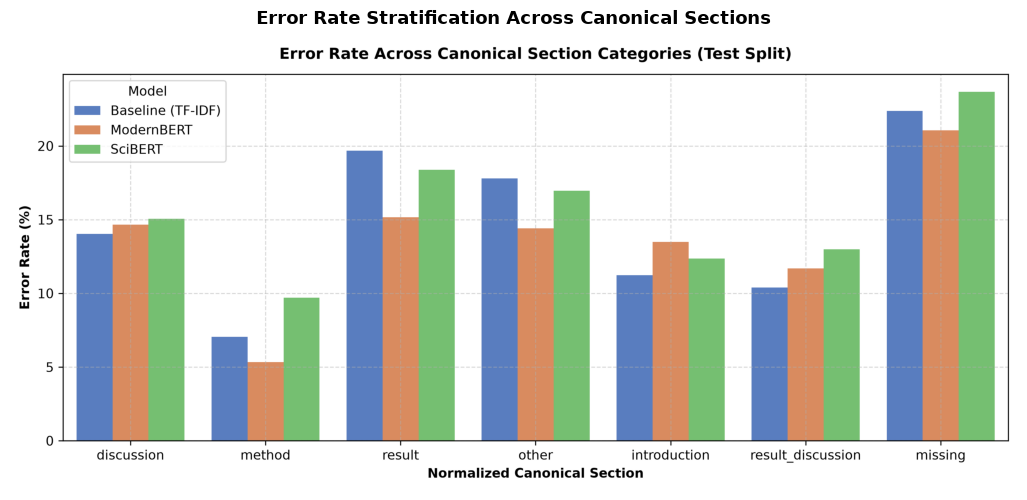

In [3]:
# Visualizing Error Rates across Section Headers
fig_path = figures_dir / "error_rate_by_section.png"
if fig_path.is_file():
    img = mpimg.imread(str(fig_path))
    plt.figure(figsize=(13, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Error Rate Stratification Across Canonical Sections", fontsize=13, fontweight="bold", pad=10)
    plt.show()
else:
    print(f"Figure not found at: {fig_path}")

#### Key Section-Level Diagnostic Observations:
- **Lowest Error Rate in `Method` Sections:** ModernBERT achieves a remarkably low **5.34% error rate** in method sections (TF-IDF with section context achieves 7.04%). The procedural phrasing in method sections provides strong corroboration.
- **Severe "Missing Section Penalty":** When section metadata is omitted (`missing`), error rates spike to **21.05% - 26.32%**, representing a **$3.5\times$ to $4.5\times$ increase** in failure probability compared to structured method sections.
- **Moderate Errors in `Discussion` (14.0% - 15.1%):** Discussion sections frequently juxtapose previous findings with the author's own discoveries, presenting dual-intent linguistic patterns that challenge both classical and deep learning models.

### 3. Inter-Class Error Transition Dynamics
To understand which semantic categories confuse the models most, we examine the directionality of prediction errors.

In [4]:
# Load error transition breakdown
transitions_df = pd.read_csv(reports_dir / "error_transitions_breakdown.csv")
display(transitions_df)

,Model,True Class,Predicted Class,Error Count,Error Rate within Class (%)
0,Baseline (TF-IDF),method,background,97,16.06
1,Baseline (TF-IDF),method,result,14,2.32
2,Baseline (TF-IDF),background,method,36,3.61
3,Baseline (TF-IDF),background,result,53,5.32
4,Baseline (TF-IDF),result,method,4,1.54
5,Baseline (TF-IDF),result,background,51,19.69
6,ModernBERT,method,background,63,10.43
7,ModernBERT,method,result,14,2.32
8,ModernBERT,background,method,47,4.72
9,ModernBERT,background,result,87,8.73


#### Confusion Directionality Analysis:
1. **`Method` Misclassified as `Background`:** In the TF-IDF baseline, 97 `method` instances (16.06%) were predicted as `background`. ModernBERT reduces this to 63 instances (10.43%), and SciBERT to 84 instances (13.91%). This occurs when a method citation introduces an algorithm or tool using declarative, descriptive syntax rather than procedural action verbs.
2. **`Result` Misclassified as `Background`:** The TF-IDF baseline misclassifies 51 `result` citations (19.69%) as `background`. In striking contrast, **SciBERT reduces this to just 13 cases (5.02%)**, demonstrating that domain-specific scientific pre-training captures outcome reporting nuances that general models and n-gram baselines miss.
3. **`Method` vs. `Result` Boundary is Crisp:** Confusions directly between `method` and `result` remain minimal across all models (typically $\le 2.5\%$ of instances), confirming that the models cleanly separate experimental protocol from empirical outcome.

### 4. Model Agreement & Disagreement: Context Rescue vs. Universal Hard Instances
Comparing instances where deep Transformer representations succeed over n-gram baselines, versus instances where all models fail simultaneously.

In [5]:
# Load rescued errors and universal hard instances
rescued_df = pd.read_csv(errors_dir / "baseline_errors_fixed_by_transformers.csv")
hard_df = pd.read_csv(errors_dir / "hard_instances_all_models_wrong.csv")

print(f"Baseline errors successfully rescued by Transformers: {len(rescued_df)} instances")
print(f"Universal hard instances (failed by ALL 4 models):        {len(hard_df)} instances ({len(hard_df) / 1859 * 100:.2f}% of test set)")

print("\nHard instances breakdown by True Label:")
print(hard_df["label_name"].value_counts())

print("\nHard instances breakdown by Section Type:")
print(hard_df["section_clean"].value_counts())

Baseline errors successfully rescued by Transformers: 78 instances
Universal hard instances (failed by ALL 4 models):        116 instances (6.24% of test set)

Hard instances breakdown by True Label:
label_name
background    56
method        53
result         7
Name: count, dtype: int64

Hard instances breakdown by Section Type:
section_clean
discussion           51
result               23
method               15
missing               9
other                 9
introduction          7
result_discussion     2
Name: count, dtype: int64


### 5. Qualitative Case Studies: Granular Linguistic Analysis
Here we review representative samples illustrating the three primary failure archetypes identified in the dataset.

In [6]:
# Load curated qualitative case studies
case_studies = pd.read_csv(errors_dir / "qualitative_case_studies.csv")

for idx, row in case_studies.iterrows():
    print("=" * 90)
    print(f"CASE STUDY #{idx+1}: {row['Error Category']}")
    print("=" * 90)
    print(f"Section:          {row['Section Header']}")
    print(f"True Label:       {row['True Label'].upper()}")
    print(f"TF-IDF Pred:      {row['Baseline Pred']}")
    print(f"ModernBERT Pred:  {row['ModernBERT Pred']}")
    print(f"SciBERT Pred:     {row['SciBERT Pred']}")
    print(f"Citation Text:\n\"{row['Citation Context']}\"")
    print(f"Linguistic Note:  {row['Linguistic Explanation']}\n")

CASE STUDY #1: 1. Context-Rescued (Method)
Section:          result
True Label:       METHOD
TF-IDF Pred:      background
ModernBERT Pred:  method
SciBERT Pred:     method
Citation Text:
"In order to activate reporter gene expression, we first treated the cells with H2O2/vanadate (pervanadate), which causes rapid and efficient STAT92E phosphorylation [32,33] (Figure S5A) and is more efficient than transient transfection of hop in activating STAT."
Linguistic Note:  Sentence describes background terminology but appears in Methods section; section context correctly steers the transformer.

CASE STUDY #2: 1. Context-Rescued (Method)
Section:          method
True Label:       METHOD
TF-IDF Pred:      background
ModernBERT Pred:  method
SciBERT Pred:     method
Citation Text:
"In diabetes mellitus, the choice of drugs or dosages is influenced by GFR.[57] Finally, we searched for articles about 8) other chronic diseases in which reduced muscle
mass (mainly due to immobility and malnutrition)

### 6. Synthesis & Key Takeaways

1. **Section Conditioning is a Structural Superpower:** Context conditioning drastically drops error rates in procedural sections (down to ~5.3% for ModernBERT in `method`). In contrast, unsectioned citations face an error rate over 21%.
2. **Scientific Domain Pretraining Excels on Result Classification:** SciBERT's scientific vocabulary and pretraining domain enable it to correctly identify `result` citations with only 5.0% confusion to `background`, compared to ~19.7% for the baseline and ~8.9% for ModernBERT.
3. **Intrinsic Human Annotation Ambiguity (~6% Ceiling):** The 116 universal hard instances (6.24%) primarily consist of dual-intent statements in `discussion` sections where authors compare their findings with previous work. These sentences are inherently multi-intent, reflecting the natural subjective limit of single-label citation intent schemes.